In [3]:
import pandas as pd
titles = pd.read_csv('./netflix_titles.csv')
titles.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
# Menampilkan ringkasan informasi dari dataset
titles.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [5]:
# Menampilkan statistik deskriptif dari dataset
titles.describe(include='all')

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [6]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = titles.isnull().sum()
missing_values[missing_values > 0]

director      2634
cast           825
country        831
date_added      10
rating           4
duration         3
dtype: int64

In [7]:
# Memisahkan missing value > 75% & < 75%
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [8]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = titles[less].select_dtypes(include=['number']).columns
titles[numeric_features]  = titles[numeric_features].fillna(titles[numeric_features].median())

In [9]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = titles[less].select_dtypes(include=['object']).columns

for column in kategorical_features:
    titles[column] = titles[column].fillna(titles[column].mode()[0])

C:\Users\danuo\AppData\Local\Temp\ipykernel_13688\3773693334.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kategorical_features = titles[less].select_dtypes(include=['object']).columns


In [10]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = titles.drop(columns=over)

In [11]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

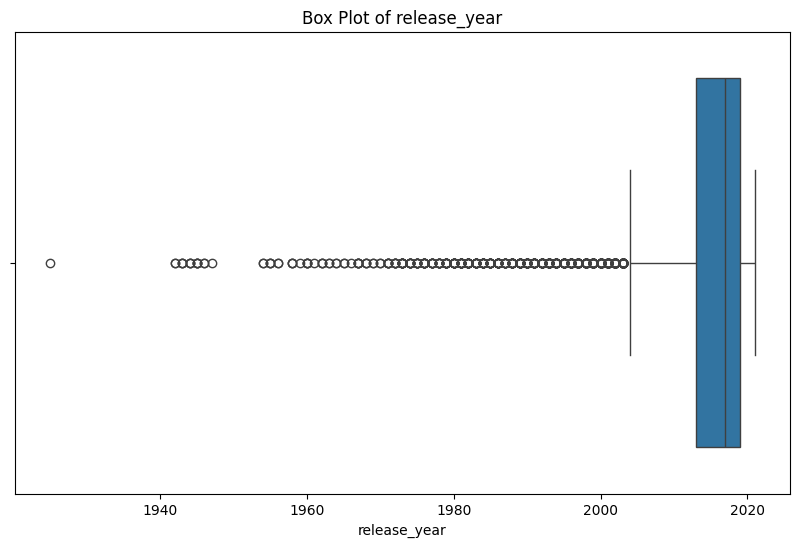

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [13]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [14]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

C:\Users\danuo\AppData\Local\Temp\ipykernel_13688\1961368722.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns


In [15]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

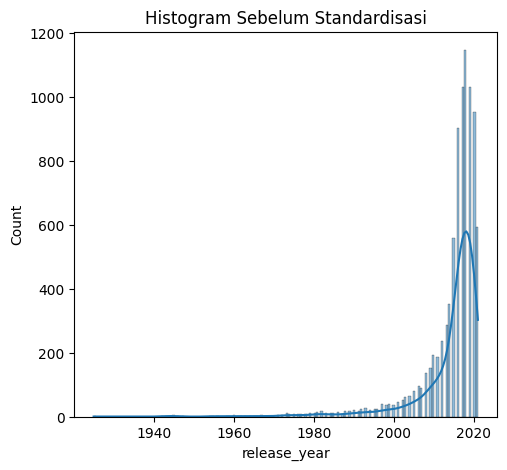

In [16]:
# Histogram Sebelum Standardisasis
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(titles[numeric_features[0]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standarisasi')

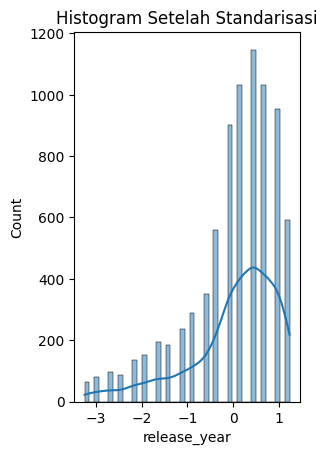

In [17]:
# Histogram setelah standarisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[0]], kde=True)
plt.title('Histogram Setelah Standarisasi')

In [18]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print('Baris duplikasi')
print(df[duplicates])

Baris duplikasi
Empty DataFrame
Columns: [release_year, show_id, type, title, cast, country, date_added, rating, duration, listed_in, description]
Index: []


In [19]:
# Menghapus baris duplikat
df = df.drop_duplicates()

print('DataFrame setelah menghapus duplikat:')
print(df)

DataFrame setelah menghapus duplikat:
      release_year show_id     type                  title  \
0         0.975877      s1    Movie   Dick Johnson Is Dead   
1         1.240022      s2  TV Show          Blood & Water   
2         1.240022      s3  TV Show              Ganglands   
3         1.240022      s4  TV Show  Jailbirds New Orleans   
4         1.240022      s5  TV Show           Kota Factory   
...            ...     ...      ...                    ...   
8802     -2.457999   s8803    Movie                 Zodiac   
8803      0.447589   s8804  TV Show            Zombie Dumb   
8804     -1.929710   s8805    Movie             Zombieland   
8805     -2.722143   s8806    Movie                   Zoom   
8806     -0.344844   s8807    Movie                 Zubaan   

                                                   cast        country  \
0                                    David Attenborough  United States   
1     Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Afric

In [20]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

C:\Users\danuo\AppData\Local\Temp\ipykernel_13688\2319133481.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = df.select_dtypes(include=['object']).columns


,show_id,type,title,cast,country,date_added,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,David Attenborough,United States,"September 25, 2021",PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",United States,"September 24, 2021",TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,David Attenborough,United States,"September 24, 2021",TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,David Attenborough,United States,"July 1, 2019",TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [21]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,release_year,show_id_s1,show_id_s10,show_id_s100,show_id_s1000,show_id_s1001,show_id_s1002,show_id_s1003,show_id_s1004,show_id_s1005,...,"description_Yugo, a 12-year-old Eliatrope with special powers, sets out on a mission to find his true family and uncover the mysteries of Wakfu.","description_Yumeko Jabami enrolls at Hyakkaou Private Academy, where students are ranked by their gambling winnings and fame and fortune awaits those on top.","description_Yusuf and his daughter set out to buy his wife an anniversary gift, a gesture demanding much patience and negotiation skills in the West Bank.","description_Zack Snyder and his ""Army of the Dead"" team dive into the film's wild stunts, groundbreaking effects and the evolution of the zombie genre.",description_Zack and Miri make and star in an adult film to bring in easy money. But their unspoken feelings for each other might threaten the whole enterprise.,description_Zenos wants to use the Earth’s negative energy for his own good – and it's up to Miniforce X to stop this space alien’s evil plans.,"description_Zig, an island-bound hyena, will do anything to get his paws on Marina the mermaid, but her devoted pal Sharko always comes to her rescue in time.","description_Zixin is about to marry Qihong, but her gallivanting ex returns to wreak havoc as mistaken identities and love triangles stir up the lovers' paradise.","description_Zoe Walker leaves her quiet life behind to investigate her brother's disappearance in Ibiza, where she quickly heads down a decadent and dangerous path.",description_“Last Chance U” hits the hardwood in East Los Angeles as a coach with strong convictions leads young men who hope to fulfill major college potential.
0,0.975877,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1.240022,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1.240022,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,1.240022,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1.240022,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8802,-2.457999,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8803,0.447589,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8804,-1.929710,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8805,-2.722143,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [22]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])
    
# Menampilkan hasil
df_lencoder

,release_year,show_id,type,title,cast,country,date_added,rating,duration,listed_in,description
0,0.975877,0,0,1823,1555,574,1697,7,191,226,2365
1,1.240022,1039,1,1007,378,405,1692,11,100,365,1612
2,1.240022,2098,1,2439,5745,574,1692,11,0,197,6752
3,1.240022,3178,1,3233,1555,574,1692,11,0,249,3343
4,1.240022,4253,1,3550,4406,240,1692,11,100,344,4074
...,...,...,...,...,...,...,...,...,...,...,...
8802,-2.457999,7960,0,8052,4284,574,1406,8,69,222,832
8803,0.447589,7961,1,8055,1555,574,781,14,100,375,7793
8804,-1.929710,7962,0,8056,2947,574,1354,8,187,162,4821
8805,-2.722143,7963,0,8059,6436,574,660,6,187,110,3059


In [23]:
df_lencoder.head()

,release_year,show_id,type,title,cast,country,date_added,rating,duration,listed_in,description
0,0.975877,0,0,1823,1555,574,1697,7,191,226,2365
1,1.240022,1039,1,1007,378,405,1692,11,100,365,1612
2,1.240022,2098,1,2439,5745,574,1692,11,0,197,6752
3,1.240022,3178,1,3233,1555,574,1692,11,0,249,3343
4,1.240022,4253,1,3550,4406,240,1692,11,100,344,4074


In [24]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0] # Menampilkan kolom dengan missing values

,Missing Values,Percentage


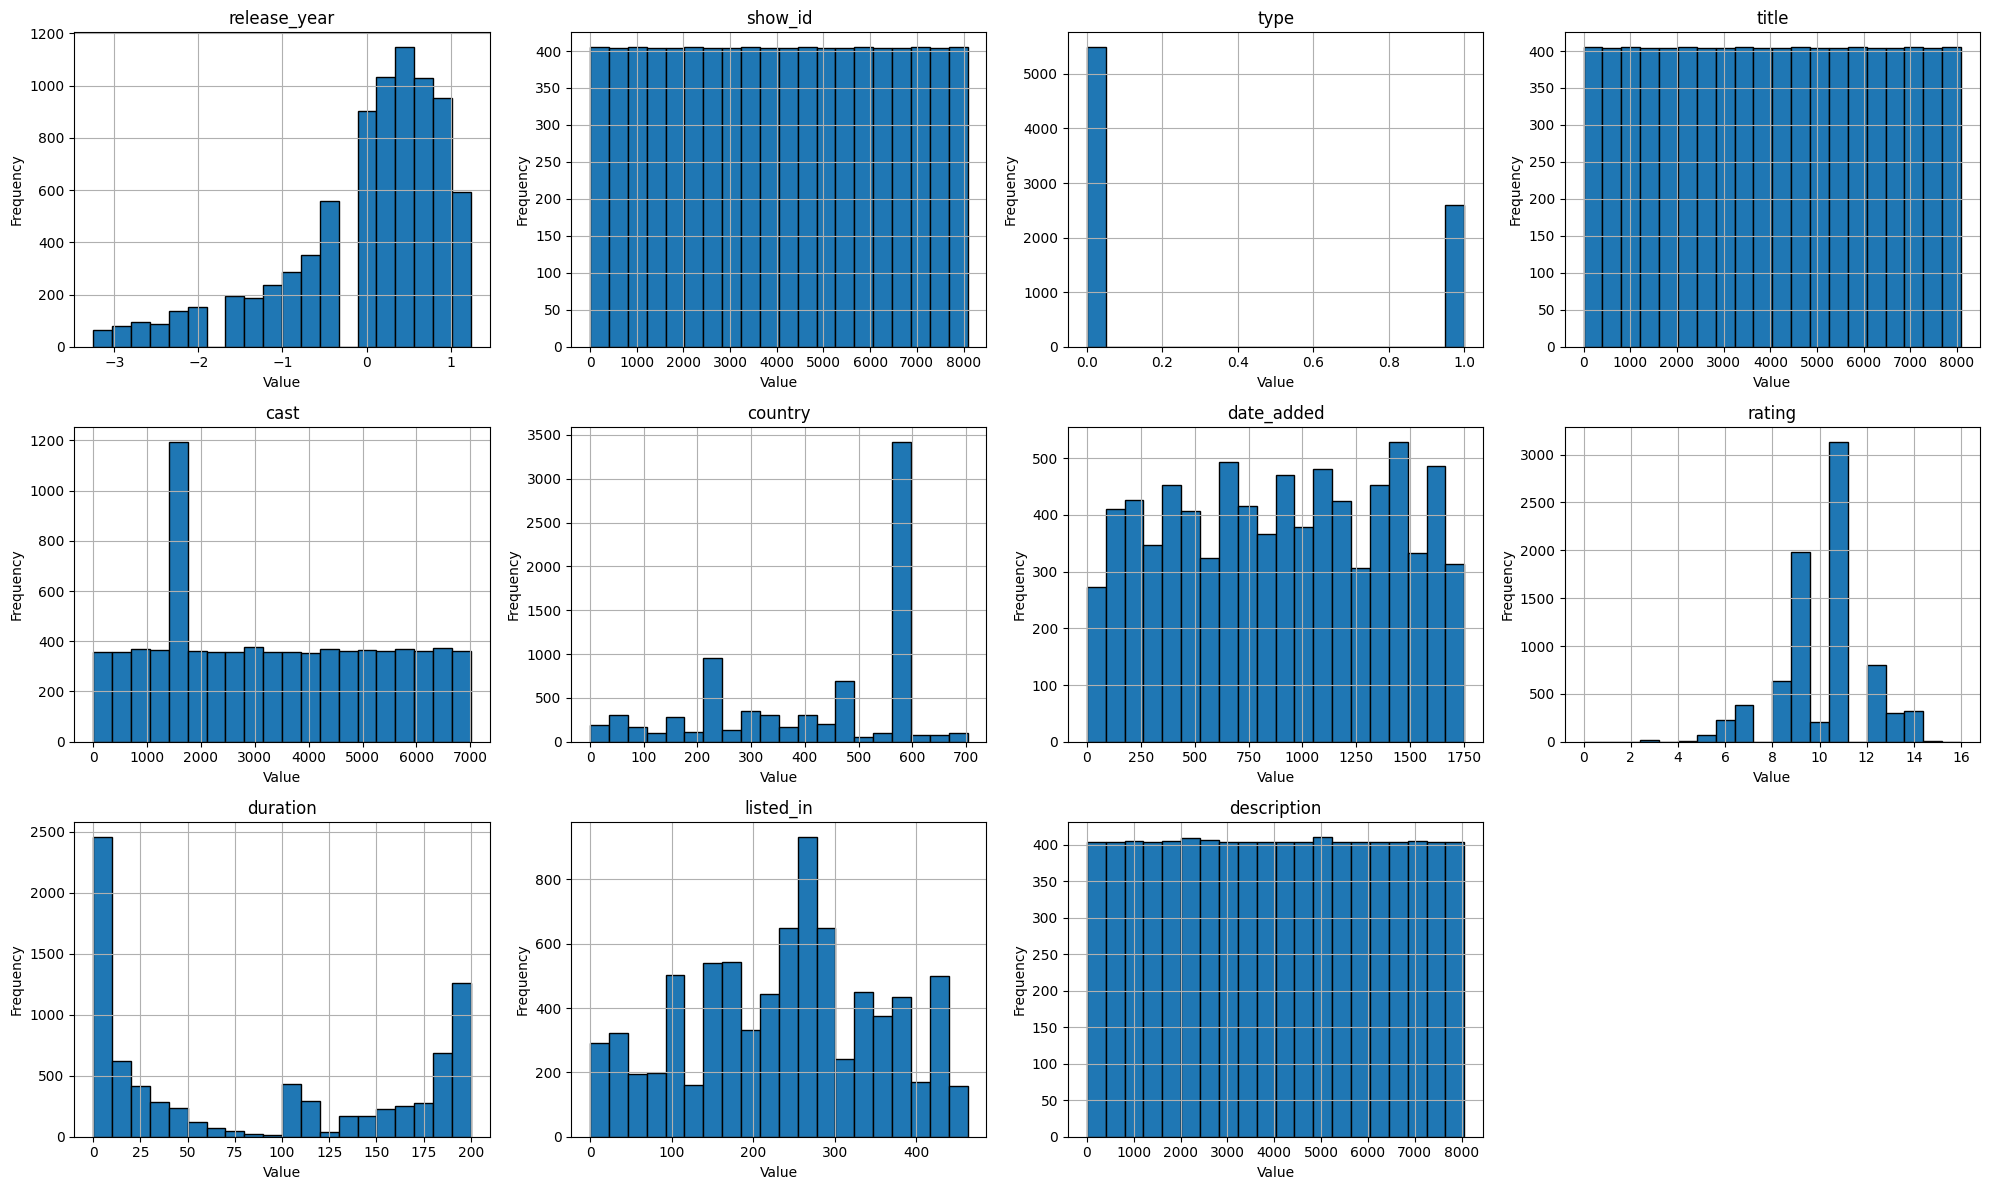

In [25]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols) # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()


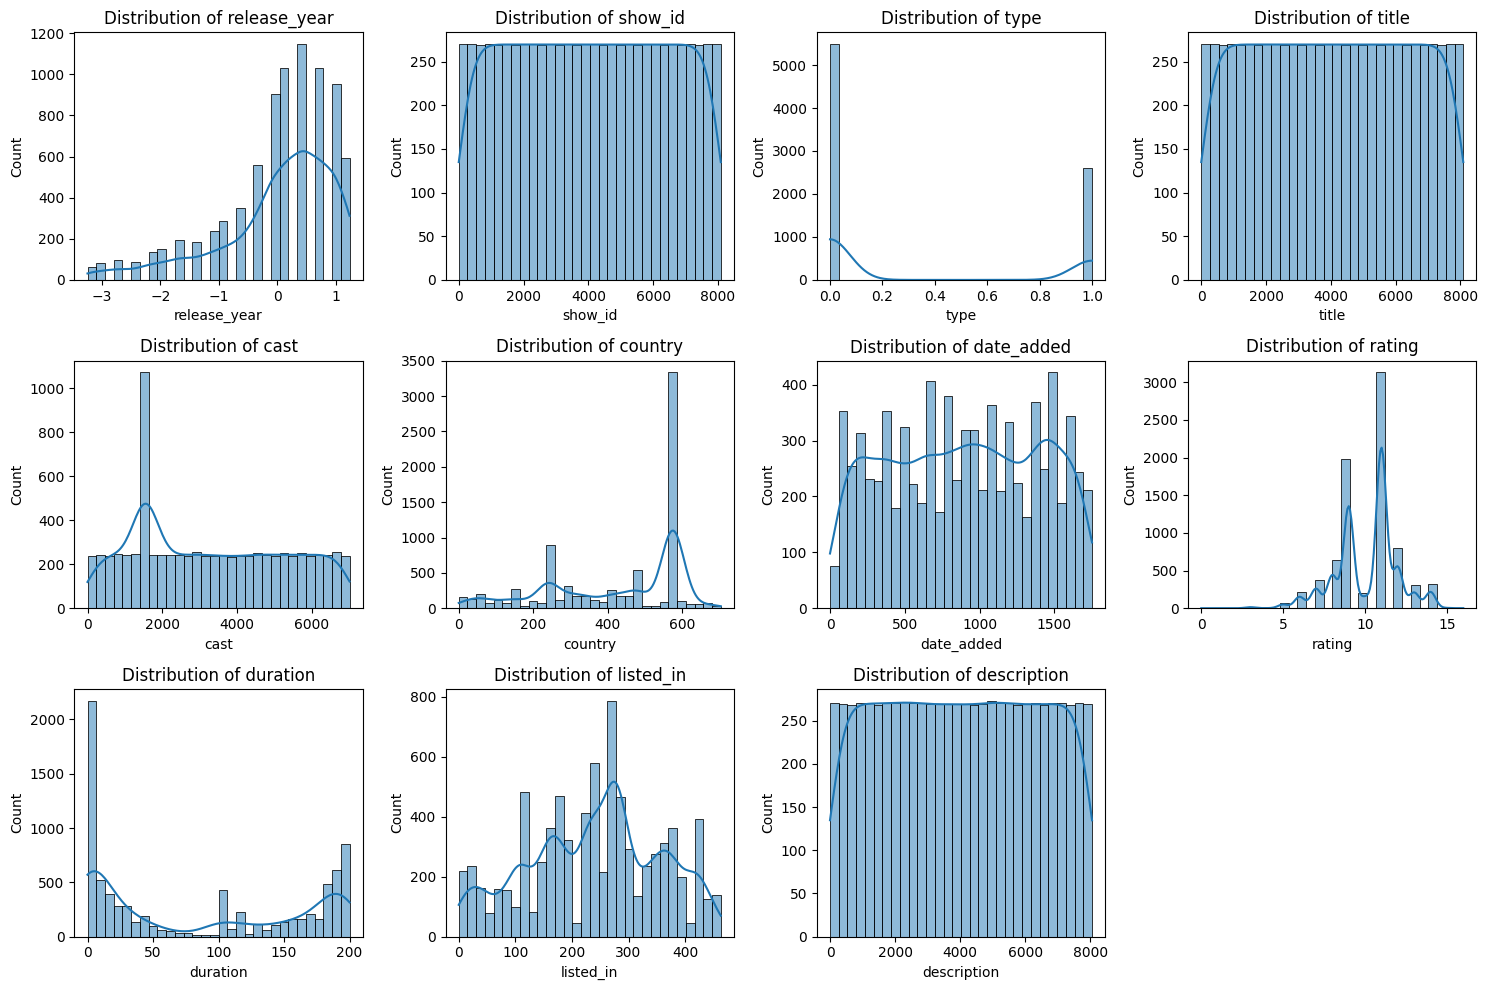

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = ['release_year', 'show_id', 'type', 'title', 'cast', 'country', 'date_added', 'rating', 'duration', 'listed_in', 'description']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(3, 4, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()



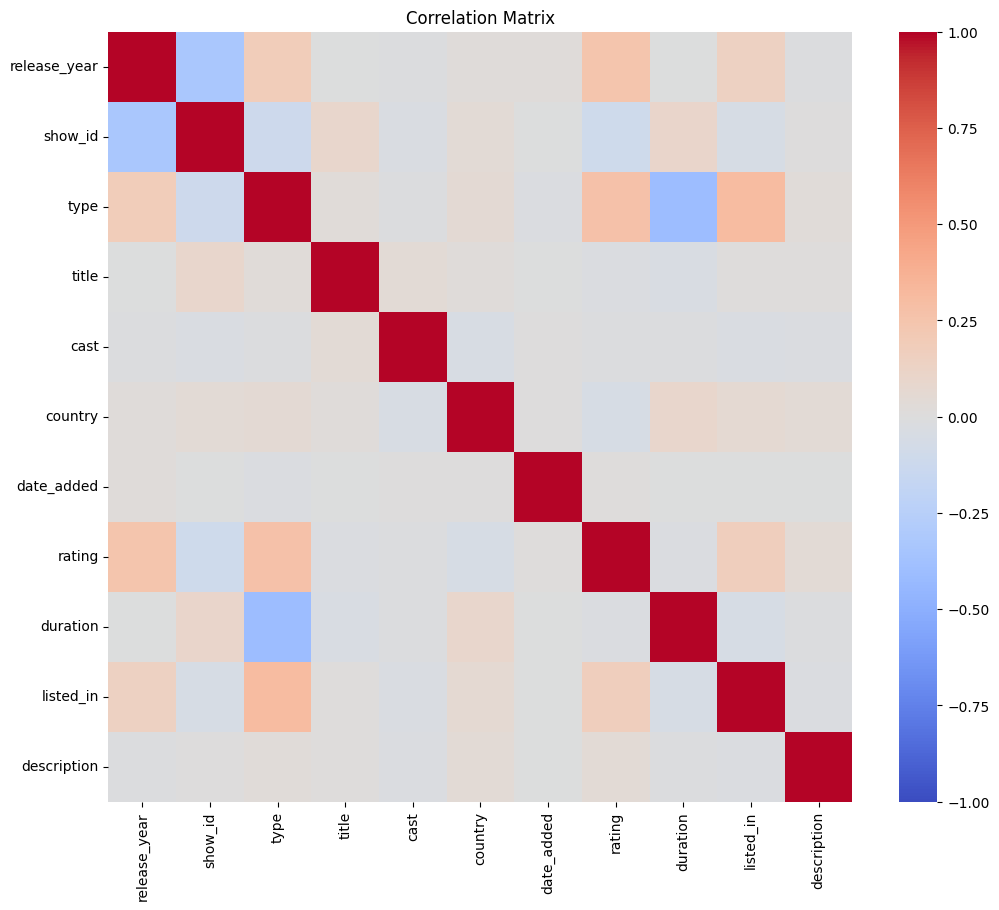

In [27]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()



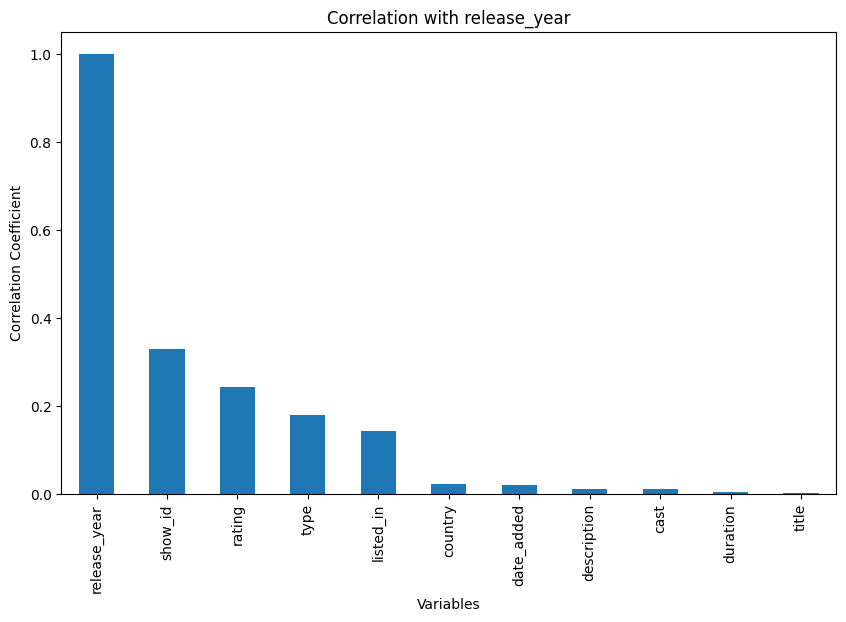

In [28]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['release_year']

# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with release_year')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

In [29]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Membaca dataset
df = pd.read_csv('netflix_titles.csv')

# Menghapus data yang targetnya kosong
df = df.dropna(subset=['release_year'])

# Memisahkan fitur (X) dan target (y)
X = df.drop(columns=['release_year', 'show_id'])
y = df['release_year']

# Membagi dataset menjadi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

# Menampilkan ukuran data
print("Jumlah seluruh data:", len(df))
print("Data training:", len(X_train))
print("Data testing:", len(X_test))

Jumlah seluruh data: 8807
Data training: 7045
Data testing: 1762


In [30]:
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

# Menentukan kolom numerik dan kategorikal
num_cols = X_train.select_dtypes(include=np.number).columns
cat_cols = X_train.select_dtypes(exclude=np.number).columns

# Preprocessing fitur
preprocessor = ColumnTransformer([
    ('num', make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler()
    ), num_cols),

    ('cat', make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False,
            min_frequency=10
        )
    ), cat_cols)
])

# Mengubah data menjadi numerik
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# Memastikan semua nilai valid
X_train = np.nan_to_num(
    X_train, nan=0.0, posinf=0.0, neginf=0.0
)
X_test = np.nan_to_num(
    X_test, nan=0.0, posinf=0.0, neginf=0.0
)

print("Data siap digunakan.")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Data siap digunakan.
X_train: (7045, 454)
X_test: (1762, 454)


In [31]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(X_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(X_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(X_train, y_train)


,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prediksi data testing menggunakan ketiga model
y_pred_lars = lars.predict(X_test)
y_pred_lr = LR.predict(X_test)
y_pred_gbr = GBR.predict(X_test)

# Menghitung metrik evaluasi
models = {
    "LARS": y_pred_lars,
    "Linear Regression": y_pred_lr,
    "Gradient Boosting": y_pred_gbr
}

for name, y_pred in models.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"\nModel: {name}")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"R2 Score: {r2:.4f}")


Model: LARS
MAE: 5.4885
MSE: 87.4635
R2 Score: 0.0410

Model: Linear Regression
MAE: 5.3098
MSE: 63.2433
R2 Score: 0.3065

Model: Gradient Boosting
MAE: 4.3866
MSE: 54.5637
R2 Score: 0.4017
